# Run the rApp — twin-in-the-loop optimisation on a Virtual RIC (v4, Mac run)

This notebook is the run engine behind the **Run the rApp** artefact page. It executes the
DigitalTwinSim rApp prototypes exactly as described in *Twin-in-the-Loop Optimisation as an
rApp on a Virtual RIC* (full description, v4): the existing configuration is first evaluated
in the twin from the ingested counter dump, candidate changes are rehearsed in the twin, and
only changes that pass the twin gate (§9) are emitted as a configuration intent.

**Engines:** Sionna RT (ray-traced twin, one isotropic trace per tower; every configuration
scored in post with the TR 38.901 pattern) and Sionna SYS (PHYAbstraction link curve and the
slice environment). **Modes:** single tower or cluster (§12). **Functions:** capacity
(twin optimiser), slice / PRB (SYS-scored guarded acceptance), audit (MCS histogram fit,
§10), energy (anchored to the validated RANOpt relationship).

**Version:** artefact v4 - run on a Mac (Apple M3 GPU, Sionna RT on Metal), 16 Nov 2026, synced with the v4 full description. This copy is saved **with its outputs**: every cell shows what it printed, and the full result - recommended changes, before/after numbers and the RSRP maps - is in the **last cell**, no run needed. Settings used: MODE = "single", FUNCTION = "all", COUNTER_SET = "study". To run it again, change the settings and Run all, as below.

**How to run.** Change the three settings in the **settings cell** below - MODE ("single" or "cluster"), FUNCTION ("capacity", "slice" (or "prb"), "energy", "audit" - one step at a time - or "all") and COUNTER_SET ("study", "test1", "test2", "test3" or "operator") - then **Runtime > Run all**. The result - the recommended changes, the before/after numbers and the maps - prints in the **last cell**. The study network (the San Francisco towers and their recorded counters) is built in: nothing to download, upload or paste. Advanced: a package copied from the [artefact page](https://ysrao.github.io/twin-in-the-loop-rapp/rapp-run.html) can be pasted over the package cell to run your own sites and counters instead. The notebook also runs locally (Jupyter on a Mac or an operator's machine): same settings, same Run all, no Google account needed.


In [1]:
# --- Setup: platform, packages, the rApp modules and the scene ----------
import os, sys, subprocess, urllib.request

import contextlib

@contextlib.contextmanager
def _quiet_backend_probe():
    # Dr.Jit (under Sionna RT) probes its CPU/LLVM backend on import and prints
    # "jitc_llvm_init(): LLVM API initialization failed" when no LLVM library is
    # installed, e.g. on a Mac. It is harmless - the GPU backend (CUDA or Metal)
    # is used - so that native message is muted here. Python errors still show.
    # Dr.Jit logs through Python's sys.stderr, native code through fd 2: mute both.
    import io
    sys.stderr.flush()
    py_err, sys.stderr = sys.stderr, io.StringIO()
    saved, null = os.dup(2), os.open(os.devnull, os.O_WRONLY)
    os.dup2(null, 2)
    try:
        yield
    finally:
        os.dup2(saved, 2); os.close(null); os.close(saved)
        sys.stderr = py_err

def _need(pkg, imp):
    try:
        with _quiet_backend_probe():
            __import__(imp)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# Test for the submodules actually used: sionna-rt alone provides only
# sionna.rt (a namespace package makes "import sionna" succeed while
# sionna.sys is still missing), so each engine is checked by name.
for pkg, imp in [("sionna-rt==2.2.0", "sionna.rt"), ("sionna==2.2.0", "sionna.sys"),
                 ("trimesh", "trimesh"), ("rtree", "rtree")]:
    _need(pkg, imp)

with _quiet_backend_probe():
    import mitsuba as mi
    import sionna.rt  # picks the ray-tracing backend: NVIDIA GPU (CUDA), Apple GPU (Metal) or CPU (LLVM)
mi.set_log_level(mi.LogLevel.Error)  # hide Mitsuba's "ASCII PLY is slow to parse" warning on the scene file
_backend = {"cuda": "NVIDIA GPU (CUDA)", "metal": "Apple GPU (Metal)", "llvm": "CPU (LLVM)"}
print("ray tracing on:", _backend.get(mi.variant().split("_")[0], mi.variant()), "-", mi.variant())

# Running from a clone of the repository (Jupyter on a Mac or an operator's
# machine): use the clone's own modules and scene. Otherwise (Colab):
# fetch them from GitHub.
_clone = next((d for d in (os.getcwd(), os.path.dirname(os.getcwd()))
               if os.path.exists(os.path.join(d, "rapp", "twin.py"))
               and os.path.exists(os.path.join(d, "data", "city_open.ply"))), None)
if _clone:
    sys.path.insert(0, os.path.join(_clone, "rapp"))
    SCENE = os.path.join(_clone, "data", "city_open.ply")
    print("modules + scene: local clone of the repository")
else:
    REPO_RAW = "https://raw.githubusercontent.com/ysrao/twin-in-the-loop-rapp/main/"
    os.makedirs("rapp", exist_ok=True)
    for f in ["twin.py", "search.py", "cluster.py", "mcs_audit.py", "env_sys.py", "policy.py"]:
        urllib.request.urlretrieve(REPO_RAW + "rapp/" + f, f"rapp/{f}")  # always fresh: a persistent runtime must not keep stale modules
    sys.path.insert(0, os.path.abspath("rapp"))
    SCENE = "city_open.ply"
    if not os.path.exists(SCENE):
        urllib.request.urlretrieve(REPO_RAW + "data/city_open.ply", SCENE)
    print("modules + scene: downloaded from GitHub")
print("scene ready:", os.path.getsize(SCENE), "bytes")

ray tracing on: Apple GPU (Metal) - metal_ad_mono_polarized
modules + scene: local clone of the repository
scene ready: 4437248 bytes


In [2]:
# --- What to run ---------------------------------------------------------
# Change these settings, then Run all. That is all a reader has to do:
# the study network (the San Francisco towers and their recorded
# counters) is already inside this notebook.
MODE = "single"       # "single" = Tower B alone | "cluster" = Towers A + B + C
FUNCTION = "all"      # run ONE step: "capacity" | "slice" (= "prb") | "energy" | "audit" - or "all"
# Advanced: to run your own sites and counters instead, build a package
# on the artefact page, click "Copy the package" there, and paste it over
# the whole of the package cell below - a pasted package overrides these
# settings (its own mode, function and counters are used).
COUNTER_SET = "study" # "study" | "test1" | "test2" | "test3" | "operator"
# The counter set to judge the existing configuration by:
#   "study"    - the study network's recorded counters (the default)
#   "test1"    - Test data 1: a loaded cell, cell-edge suffering
#   "test2"    - Test data 2: a quiet cell, many low-traffic hours
#   "test3"    - Test data 3: an edge-poor cell, low fairness
#   "operator" - Operator added: your own counter dump, edited in below
OPERATOR_COUNTERS = {
    "median_dl": 38.0, "median_ul": 11.0, "edge_dl": 6.5, "edge_ul": 2.0,
    "fairness": 0.41, "prb_util": 81.0, "signalling": 34.0, "load": 0.75,
    "low_hours": 6, "carriers_per_site": 2, "current_shares": [0.6, 0.2, 0.2],
}  # <- operator: replace these numbers with your own counter dump
PM_CSV = ""  # MCS audit input: "" = the built-in MCS histograms, or a CSV file path,
# e.g. PM_CSV = "../data/test_pm_mcs.csv" (paths are relative to this notebook's folder).
# One row per sector and MCS index, with these columns:
#   site_id, sector (1-3), mcs (0-27), grant_share, olla_offset_db, mcs_cap
# grant_share is each MCS index's share of the sector's grants (normalised per sector);
# olla_offset_db and mcs_cap are the gNB's configured values (same on every row).


In [3]:
# --- The run package: sites + existing config + counters + function ----
# This cell is ONLY the package. On the artefact page, choose the mode and
# the function and click "Copy the package" - the copied text is this whole
# cell. Click this cell, select all (Cmd/Ctrl+A) and paste over it.
# Leave the cell as it is to run the built-in study case.
PACKAGE_JSON = r'''
{
 "mode": "single",
 "function": "capacity",
 "sites": [
  {
   "site_id": "sf-twin-tower-B",
   "label": "Tower B",
   "position_enu_m": [
    250.0,
    250.0
   ],
   "ground_z_m": -64.75,
   "height_m_agl": 30.0,
   "azimuths_deg": [
    90.0,
    210.0,
    330.0
   ],
   "tilts_deg": [
    10.0,
    0.97,
    3.92
   ],
   "power_offset_db": 0.0,
   "traffic_shares_current": [
    0.4,
    0.35,
    0.25
   ],
   "eval_half_m": 150.0,
   "eval_step_m": 20.0
  }
 ],
 "site_traffic_totals": {
  "sf-twin-tower-B": 1.0
 },
 "policy": {
  "traffic_shares_projected": [
   0.34,
   0.3,
   0.36
  ],
  "min_coverage_delta_pts": 0.0,
  "max_edge_drop_db": 1.0
 },
 "counters": {
  "median_dl": 38.0,
  "median_ul": 11.0,
  "edge_dl": 6.5,
  "edge_ul": 2.0,
  "fairness": 0.41,
  "prb_util": 81.0,
  "signalling": 34.0,
  "load": 0.75,
  "low_hours": 6,
  "carriers_per_site": 2,
  "current_shares": [
   0.6,
   0.2,
   0.2
  ]
 },
 "pm": {
  "site_id": "sf-twin-tower-B",
  "gnb_configured": {
   "olla_offset_db": 0.0,
   "mcs_cap": 24
  },
  "mcs_histograms_by_sector": {
   "0": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.04395,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0219,
    0.0,
    0.06445,
    0.0,
    0.0,
    0.0203,
    0.17165,
    0.0444,
    0.2833,
    0.0,
    0.3042,
    0.04585,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
   ],
   "1": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.02455,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.09245,
    0.0,
    0.0,
    0.0466,
    0.04535,
    0.069,
    0.21025,
    0.0,
    0.2549,
    0.2569,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
   ],
   "2": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0381,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0777,
    0.0,
    0.0,
    0.11125,
    0.07655,
    0.07875,
    0.11735,
    0.0,
    0.2711,
    0.194,
    0.0352,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
   ]
  }
 }
}
'''


In [4]:
import json as _json, copy as _copy
try:
    _pasted = _json.loads(PACKAGE_JSON)
except Exception:
    raise ValueError("The package cell does not hold valid JSON - if you pasted a "
                     "package from the artefact page, the paste went wrong: click "
                     "'Copy the package' there, click the package cell here, select "
                     "all (Cmd/Ctrl+A) and paste over the whole cell, then Run all again.")
STUDY_PACKAGES = {"single": {'mode': 'single', 'function': 'capacity', 'sites': [{'site_id': 'sf-twin-tower-B', 'label': 'Tower B', 'position_enu_m': [250, 250], 'ground_z_m': -64.75, 'height_m_agl': 30, 'azimuths_deg': [90, 210, 330], 'tilts_deg': [10, 0.97, 3.92], 'power_offset_db': 0, 'traffic_shares_current': [0.4, 0.35, 0.25], 'eval_half_m': 150, 'eval_step_m': 20}], 'site_traffic_totals': {'sf-twin-tower-B': 1}, 'policy': {'traffic_shares_projected': [0.34, 0.3, 0.36], 'min_coverage_delta_pts': 0, 'max_edge_drop_db': 1}, 'counters': {'median_dl': 38, 'median_ul': 11, 'edge_dl': 6.5, 'edge_ul': 2, 'fairness': 0.41, 'prb_util': 81, 'signalling': 34, 'load': 0.75, 'low_hours': 6, 'carriers_per_site': 2, 'current_shares': [0.6, 0.2, 0.2]}, 'pm': {'site_id': 'sf-twin-tower-B', 'gnb_configured': {'olla_offset_db': 0, 'mcs_cap': 24}, 'mcs_histograms_by_sector': {'0': [0, 0, 0, 0, 0, 0.04395, 0, 0, 0, 0, 0.0219, 0, 0.06445, 0, 0, 0.0203, 0.17165, 0.0444, 0.2833, 0, 0.3042, 0.04585, 0, 0, 0, 0, 0, 0], '1': [0, 0, 0, 0, 0, 0.02455, 0, 0, 0, 0, 0, 0, 0.09245, 0, 0, 0.0466, 0.04535, 0.069, 0.21025, 0, 0.2549, 0.2569, 0, 0, 0, 0, 0, 0], '2': [0, 0, 0, 0, 0, 0.0381, 0, 0, 0, 0, 0, 0, 0.0777, 0, 0, 0.11125, 0.07655, 0.07875, 0.11735, 0, 0.2711, 0.194, 0.0352, 0, 0, 0, 0, 0]}}}, "cluster": {'mode': 'cluster', 'function': 'capacity', 'sites': [{'site_id': 'sf-twin-tower-A', 'label': 'Tower A', 'position_enu_m': [-250, 250], 'ground_z_m': -12.67, 'height_m_agl': 30, 'azimuths_deg': [90, 210, 330], 'tilts_deg': [7.9, 6.45, 10], 'power_offset_db': 0, 'traffic_shares_current': [0.38, 0.34, 0.28], 'eval_half_m': 150, 'eval_step_m': 20}, {'site_id': 'sf-twin-tower-B', 'label': 'Tower B', 'position_enu_m': [250, 250], 'ground_z_m': -64.75, 'height_m_agl': 30, 'azimuths_deg': [90, 210, 330], 'tilts_deg': [10, 0.97, 3.92], 'power_offset_db': 0, 'traffic_shares_current': [0.4, 0.35, 0.25], 'eval_half_m': 150, 'eval_step_m': 20}, {'site_id': 'sf-twin-tower-C', 'label': 'Tower C', 'position_enu_m': [0, -250], 'ground_z_m': -38.89, 'height_m_agl': 30, 'azimuths_deg': [90, 210, 330], 'tilts_deg': [7.59, 7.68, 3.23], 'power_offset_db': 0, 'traffic_shares_current': [0.36, 0.33, 0.31], 'eval_half_m': 150, 'eval_step_m': 20}], 'site_traffic_totals': {'sf-twin-tower-A': 0.3, 'sf-twin-tower-B': 0.4, 'sf-twin-tower-C': 0.3}, 'policy': {'traffic_shares_projected': {'sf-twin-tower-A': [0.34, 0.33, 0.33], 'sf-twin-tower-B': [0.34, 0.3, 0.36], 'sf-twin-tower-C': [0.32, 0.32, 0.36]}, 'min_coverage_delta_pts': 0, 'max_edge_drop_db': 1}, 'counters': {'median_dl': 38, 'median_ul': 11, 'edge_dl': 6.5, 'edge_ul': 2, 'fairness': 0.41, 'prb_util': 81, 'signalling': 34, 'load': 0.75, 'low_hours': 6, 'carriers_per_site': 2, 'current_shares': [0.6, 0.2, 0.2]}, 'pm': {'site_id': 'sf-twin-tower-B', 'gnb_configured': {'olla_offset_db': 0, 'mcs_cap': 24}, 'mcs_histograms_by_sector': {'0': [0, 0, 0, 0, 0, 0.04395, 0, 0, 0, 0, 0.0219, 0, 0.06445, 0, 0, 0.0203, 0.17165, 0.0444, 0.2833, 0, 0.3042, 0.04585, 0, 0, 0, 0, 0, 0], '1': [0, 0, 0, 0, 0, 0.02455, 0, 0, 0, 0, 0, 0, 0.09245, 0, 0, 0.0466, 0.04535, 0.069, 0.21025, 0, 0.2549, 0.2569, 0, 0, 0, 0, 0, 0], '2': [0, 0, 0, 0, 0, 0.0381, 0, 0, 0, 0, 0, 0, 0.0777, 0, 0, 0.11125, 0.07655, 0.07875, 0.11735, 0, 0.2711, 0.194, 0.0352, 0, 0, 0, 0, 0]}}}}
if _pasted == STUDY_PACKAGES["single"]:
    _mode = str(MODE).strip().lower()
    _fn = str(FUNCTION).strip().lower()
    _fn = {"prb": "slice", "slice/prb": "slice", "slices": "slice"}.get(_fn, _fn)  # "prb" = the slice / PRB step
    if _mode not in STUDY_PACKAGES:
        raise ValueError('MODE must be "single" or "cluster" - the settings cell has %r.' % (MODE,))
    if _fn not in ("capacity", "slice", "energy", "audit", "all"):
        raise ValueError('FUNCTION must be "capacity", "slice" (or "prb"), "energy", "audit" or "all" - the settings cell has %r.' % (FUNCTION,))
    PKG = _copy.deepcopy(STUDY_PACKAGES[_mode])
    PKG["function"] = _fn
    print("settings cell: study network,", _mode, "mode,", _fn, "function")
    TEST_COUNTERS = {
        "test1": {"median_dl": 52.0, "median_ul": 17.0, "edge_dl": 4.1, "edge_ul": 1.2,
                  "fairness": 0.33, "prb_util": 93.0, "signalling": 41.0, "load": 0.92,
                  "low_hours": 3, "carriers_per_site": 3, "current_shares": [0.7, 0.15, 0.15]},
        "test2": {"median_dl": 18.0, "median_ul": 6.0, "edge_dl": 9.0, "edge_ul": 3.0,
                  "fairness": 0.71, "prb_util": 44.0, "signalling": 22.0, "load": 0.35,
                  "low_hours": 9, "carriers_per_site": 2, "current_shares": [0.5, 0.25, 0.25]},
        "test3": {"median_dl": 29.0, "median_ul": 9.0, "edge_dl": 2.8, "edge_ul": 0.9,
                  "fairness": 0.28, "prb_util": 77.0, "signalling": 38.0, "load": 0.68,
                  "low_hours": 5, "carriers_per_site": 2, "current_shares": [0.55, 0.3, 0.15]},
    }
    _cs = str(COUNTER_SET).strip().lower()
    if _cs == "operator":
        PKG["counters"] = _copy.deepcopy(OPERATOR_COUNTERS)
        print("counters: Operator added (the OPERATOR_COUNTERS in the settings cell)")
    elif _cs in TEST_COUNTERS:
        PKG["counters"] = _copy.deepcopy(TEST_COUNTERS[_cs])
        print("counters: Test data", _cs[-1], "(built-in test set)")
    elif _cs != "study":
        raise ValueError('COUNTER_SET must be "study", "test1", "test2", "test3" or "operator" - the settings cell has %r.' % (COUNTER_SET,))
    else:
        print("counters: the study network's recorded counters")
else:
    PKG = _pasted
    print("package: pasted from the artefact page")
# --- Optional: MCS histograms from a PM CSV (the PM_CSV setting) ---------
_pm_csv = str(globals().get("PM_CSV", "") or "").strip()
if _pm_csv:
    import csv as _csv, os as _os
    if not _os.path.exists(_pm_csv):
        raise FileNotFoundError(f"PM_CSV: no file at {_pm_csv!r} (looked in {_os.getcwd()}). "
                                "Use a path relative to this notebook's folder, e.g. '../data/test_pm_mcs.csv'.")
    with open(_pm_csv, newline="") as _f:
        _rows = list(_csv.DictReader(_f))
    _need_cols = {"site_id", "sector", "mcs", "grant_share", "olla_offset_db", "mcs_cap"}
    if not _rows or not _need_cols <= set(_rows[0]):
        raise ValueError(f"PM_CSV {_pm_csv!r} needs the columns {sorted(_need_cols)}; "
                         f"it has {sorted(_rows[0]) if _rows else 'no rows'}.")
    _sites = {r["site_id"] for r in _rows}
    if len(_sites) != 1 or next(iter(_sites)) not in [s["site_id"] for s in PKG["sites"]]:
        raise ValueError(f"PM_CSV site_id must be one site of this run "
                         f"({[s['site_id'] for s in PKG['sites']]}); the file has {sorted(_sites)}.")
    _h = {str(s): [0.0] * 28 for s in range(3)}
    for _r in _rows:
        _sec, _m = int(_r["sector"]) - 1, int(_r["mcs"])
        if _sec not in (0, 1, 2) or not 0 <= _m <= 27:
            raise ValueError(f"PM_CSV row has sector {_r['sector']} / mcs {_r['mcs']}: sector must be 1-3, mcs 0-27.")
        _h[str(_sec)][_m] += float(_r["grant_share"])
    for _s, _v in _h.items():
        _tot = sum(_v)
        if _tot <= 0:
            raise ValueError(f"PM_CSV has no grants for sector {int(_s) + 1}.")
        _h[_s] = [x / _tot for x in _v]
    PKG["pm"] = {"site_id": next(iter(_sites)),
                 "gnb_configured": {"olla_offset_db": float(_rows[0]["olla_offset_db"]),
                                    "mcs_cap": int(float(_rows[0]["mcs_cap"]))},
                 "mcs_histograms_by_sector": _h}
    print(f"MCS histograms: from {_pm_csv} ({len(_rows)} rows, site {PKG['pm']['site_id']})")
MODE = PKG.get("mode", "single")
FUNCTION = PKG.get("function", "capacity")
print("mode:", MODE, "| function:", FUNCTION, "| sites:", [s["site_id"] for s in PKG["sites"]])

# --- Shared helpers -------------------------------------------------------
import numpy as np
import twin as twin_mod
from search import optimise
from cluster import ClusterScorer, optimise_cluster

PLY = SCENE
RESULT = {"mode": MODE, "function": FUNCTION, "changes": [], "notes": []}
_traces = {}

def trace_for(site, rx, tag):
    key = (site["site_id"], tag)
    if key not in _traces:
        tx = [site["position_enu_m"][0], site["position_enu_m"][1],
              site["ground_z_m"] + site["height_m_agl"]]
        _traces[key] = twin_mod.trace_tower(PLY, tx, rx)
        print(f"trace {site['site_id']} ({tag}): {_traces[key]['trace_s']:.1f}s, {len(rx)} receivers")
    return _traces[key]

def cfg_of(site):
    return {"azimuths": list(site["azimuths_deg"]), "tilts": list(site["tilts_deg"]),
            "power_offset_db": float(site.get("power_offset_db", 0.0))}

def fmt_k(k):
    return (f"coverage {k['coverage_pct']:.1f}%  median RSRP {k['median_rsrp']:.1f} dBm  "
            f"edge p5 {k['edge_rsrp_p5']:.1f}  median SINR {k['median_sinr']:.1f} dB  "
            f"weighted SE {k['capacity_weighted_se']:.2f} bit/s/Hz")

def describe_changes(before, after):
    out = []
    for sid in before:
        b, a = before[sid], after[sid]
        lbl = sid.replace("sf-twin-tower-", "Tower ")
        for s in range(3):
            if a["azimuths"][s] != b["azimuths"][s]:
                out.append(f"{lbl} sector {s+1}: azimuth {b['azimuths'][s]:.0f} -> {a['azimuths'][s]:.0f} deg")
            if a["tilts"][s] != b["tilts"][s]:
                out.append(f"{lbl} sector {s+1}: tilt {b['tilts'][s]:.2f} -> {a['tilts'][s]:.0f} deg")
        if a.get("power_offset_db", 0.0) != b.get("power_offset_db", 0.0):
            out.append(f"{lbl}: power offset {b.get('power_offset_db',0.0):+.0f} -> {a.get('power_offset_db',0.0):+.0f} dB")
    return out

def clean(x):
    return None if x is None or (isinstance(x, float) and not np.isfinite(x)) else round(float(x), 2)

settings cell: study network, single mode, all function
counters: the study network's recorded counters
mode: single | function: all | sites: ['sf-twin-tower-B']


In [5]:
if "RESULT" not in globals():
    raise RuntimeError("This cell needs the setup cells above it. The kernel was restarted, or "
                       "cells 1-4 have not run yet: use Run > Run All Cells (or run cells 1-4 "
                       "first, then this one).")
# --- Capacity: the twin optimiser (Sionna RT + SYS link curve) -----------
if FUNCTION in ("capacity", "all"):
    policy = PKG["policy"]
    if MODE == "single":
        site = PKG["sites"][0]
        tx = [site["position_enu_m"][0], site["position_enu_m"][1],
              site["ground_z_m"] + site["height_m_agl"]]
        rx = twin_mod.street_receivers(PLY, tx[0], tx[1],
                                       half=site.get("eval_half_m", 150.0),
                                       step=site.get("eval_step_m", 20.0))
        scorer = twin_mod.TwinScorer(trace_for(site, rx, "site"), tx[:2])
        base = cfg_of(site)
        w_cur = twin_mod.traffic_weights(scorer, base, site["traffic_shares_current"])
        w_proj = twin_mod.traffic_weights(scorer, base, policy["traffic_shares_projected"])
        base_proj = scorer.score(base, w_proj)
        best, _, best_proj, best_cur, hist = optimise(scorer, base, w_proj, w_cur, policy)
        improved = best != base
        chosen = best if improved else base
        chosen_proj = best_proj if improved else base_proj
        print("AS-BUILT  (projected traffic):", fmt_k(base_proj))
        print("OPTIMISED (projected traffic):", fmt_k(chosen_proj))
        print("provenance:", "twin_guarded_accept" if improved else "no_improvement_keep_as_built",
              f"| candidates evaluated: {len(hist)}")
        Rb = scorer.sector_rsrp(base); Ra = scorer.sector_rsrp(chosen)
        mb = np.nanmax(np.where(np.isnan(Rb), -np.inf, Rb), axis=1)
        ma = np.nanmax(np.where(np.isnan(Ra), -np.inf, Ra), axis=1)
        RESULT.update({
            "configs_before": {site["site_id"]: base}, "configs_after": {site["site_id"]: chosen},
            "kpis_before": base_proj, "kpis_after": chosen_proj,
            "changes": describe_changes({site["site_id"]: base}, {site["site_id"]: chosen}),
            "provenance": "twin_guarded_accept" if improved else "no_improvement_keep_as_built",
            "maps": {"x": [clean(v) for v in rx[:, 0]], "y": [clean(v) for v in rx[:, 1]],
                     "before": [clean(v) for v in mb], "after": [clean(v) for v in ma]}})
    else:
        sites = PKG["sites"]
        rx = twin_mod.street_receivers(PLY, 0.0, 0.0, half=480.0, step=40.0)
        traces = {s["site_id"]: trace_for(s, rx, "cluster") for s in sites}
        scorer = ClusterScorer(traces, sites)
        base_configs = {s["site_id"]: cfg_of(s) for s in sites}
        totals = PKG["site_traffic_totals"]
        cur = {s["site_id"]: s["traffic_shares_current"] for s in sites}
        proj = policy["traffic_shares_projected"]
        w_cur = scorer.traffic_weights(base_configs, totals, cur)
        w_proj = scorer.traffic_weights(base_configs, totals, proj)
        base_proj = scorer.score(base_configs, w_proj)
        best, _, best_proj, best_cur, hist = optimise_cluster(scorer, base_configs, w_proj, w_cur, policy)
        improved = best != base_configs
        chosen = best if improved else base_configs
        chosen_proj = best_proj if improved else base_proj
        print("AS-BUILT  (projected traffic):", fmt_k(base_proj))
        print("OPTIMISED (projected traffic):", fmt_k(chosen_proj))
        print("provenance:", "twin_guarded_accept_cluster" if improved else "no_improvement_keep_as_built",
              f"| candidates evaluated: {len(hist)}")
        Rb = scorer.joint_rsrp(base_configs); Ra = scorer.joint_rsrp(chosen)
        mb = np.nanmax(np.where(np.isnan(Rb), -np.inf, Rb), axis=1)
        ma = np.nanmax(np.where(np.isnan(Ra), -np.inf, Ra), axis=1)
        RESULT.update({
            "configs_before": base_configs, "configs_after": chosen,
            "kpis_before": base_proj, "kpis_after": chosen_proj,
            "changes": describe_changes(base_configs, chosen),
            "provenance": "twin_guarded_accept_cluster" if improved else "no_improvement_keep_as_built",
            "per_site_served_coverage": {
                sid: {"before": base_proj["coverage_by_serving_site"].get(sid),
                      "after": chosen_proj["coverage_by_serving_site"].get(sid)}
                for sid in base_configs},
            "maps": {"x": [clean(v) for v in rx[:, 0]], "y": [clean(v) for v in rx[:, 1]],
                     "before": [clean(v) for v in mb], "after": [clean(v) for v in ma]}})
    for c in RESULT["changes"]:
        print(" change:", c)

trace sf-twin-tower-B (site): 0.4s, 134 receivers
AS-BUILT  (projected traffic): coverage 80.6%  median RSRP -79.5 dBm  edge p5 -108.5  median SINR 14.0 dB  weighted SE 3.51 bit/s/Hz
OPTIMISED (projected traffic): coverage 85.8%  median RSRP -76.6 dBm  edge p5 -106.3  median SINR 15.5 dB  weighted SE 3.73 bit/s/Hz
provenance: twin_guarded_accept | candidates evaluated: 122
 change: Tower B sector 1: azimuth 90 -> 95 deg
 change: Tower B sector 2: azimuth 210 -> 220 deg
 change: Tower B sector 2: tilt 0.97 -> 4 deg
 change: Tower B sector 3: azimuth 330 -> 320 deg
 change: Tower B sector 3: tilt 3.92 -> 4 deg
 change: Tower B: power offset +0 -> +2 dB


In [12]:
if "RESULT" not in globals():
    raise RuntimeError("This cell needs the setup cells above it. The kernel was restarted, or "
                       "cells 1-4 have not run yet: use Run > Run All Cells (or run cells 1-4 "
                       "first, then this one).")
# --- Slice / PRB: existing reward from the counters, SYS-scored choice ---
if FUNCTION in ("slice", "all"):
    import policy as pol
    from env_sys import SysCellEnv
    c = PKG["counters"]
    kpi_now = np.array([c["median_dl"], c["median_ul"], c["edge_dl"], c["edge_ul"],
                        c["fairness"], c["prb_util"], c["signalling"]], dtype=float)
    r_now = pol.reward(kpi_now)
    print(f"EXISTING (from the ingested counters): reward {r_now:.2f} "
          f"| shares {[round(v,2) for v in c['current_shares']]}")
    env = SysCellEnv(n_users=30, n_slots=100, seed=11)
    rows = []
    for i, (name, shares, sched) in enumerate(pol.PROFILES):
        k = env.evaluate(i)
        rows.append({"name": name, "shares": list(shares), "scheduler": sched,
                     "kpis": [round(float(v), 2) for v in k], "reward": round(pol.reward(k), 2)})
        print(f"  {name:16s} shares {shares}  reward {rows[-1]['reward']:.2f}  "
              f"median DL {k[0]:.1f}  edge DL {k[2]:.1f}  fairness {k[4]:.2f}")
    cur_idx = int(np.argmin([sum(abs(np.array(sh) - np.array(c["current_shares"])))
                             for _, sh, _ in pol.PROFILES]))
    cur = rows[cur_idx]
    ok = [r for r in rows if r["reward"] > cur["reward"]
          and r["kpis"][2] >= 0.95 * cur["kpis"][2] and r["kpis"][4] >= cur["kpis"][4] - 0.02]
    chosen = max(ok, key=lambda r: r["reward"]) if ok else cur
    prov = "policy_guarded_accept" if chosen is not cur else "guarded_reject_keep_current_profile"
    print("CHOSEN:", chosen["name"], "| provenance:", prov)
    RESULT["slice"] = {"counters_reward": round(r_now, 2), "profiles": rows,
                       "current_profile": cur["name"], "chosen_profile": chosen["name"],
                       "provenance": prov}
    RESULT["changes"] = [x for x in RESULT["changes"] if not x.startswith("Slice profile ")]
    if chosen is not cur:
        RESULT["changes"].append(
            f"Slice profile {cur['name']} -> {chosen['name']}: PRB shares "
            f"{[round(v,2) for v in cur['shares']]} -> {[round(v,2) for v in chosen['shares']]}, "
            f"scheduler {chosen['scheduler']}")

EXISTING (from the ingested counters): reward 36.55 | shares [0.6, 0.2, 0.2]
  balanced         shares [0.6, 0.2, 0.2]  reward 34.12  median DL 5.5  edge DL 1.3  fairness 0.64
  dl_heavy         shares [0.75, 0.15, 0.1]  reward 31.58  median DL 3.6  edge DL 0.6  fairness 0.50
  edge_protect     shares [0.5, 0.25, 0.25]  reward 34.32  median DL 4.1  edge DL 1.5  fairness 0.67
  fairness_first   shares [0.45, 0.25, 0.3]  reward 34.68  median DL 4.8  edge DL 1.7  fairness 0.68
  urllc_priority   shares [0.4, 0.45, 0.15]  reward 35.19  median DL 4.9  edge DL 1.1  fairness 0.73
  energy_lean      shares [0.55, 0.2, 0.25]  reward 34.13  median DL 4.1  edge DL 0.7  fairness 0.67
CHOSEN: fairness_first | provenance: policy_guarded_accept


In [7]:
if "RESULT" not in globals():
    raise RuntimeError("This cell needs the setup cells above it. The kernel was restarted, or "
                       "cells 1-4 have not run yet: use Run > Run All Cells (or run cells 1-4 "
                       "first, then this one).")
# --- Audit: twin reference MCS vs the PM histogram (v4 section 10) -------
if FUNCTION in ("audit", "all"):
    import mcs_audit
    pm = PKG["pm"]
    site = next(s for s in PKG["sites"] if s["site_id"] == pm["site_id"])
    tx = [site["position_enu_m"][0], site["position_enu_m"][1],
          site["ground_z_m"] + site["height_m_agl"]]
    rx = twin_mod.street_receivers(PLY, tx[0], tx[1],
                                   half=site.get("eval_half_m", 150.0),
                                   step=site.get("eval_step_m", 20.0))
    scorer = twin_mod.TwinScorer(trace_for(site, rx, "site"), tx[:2])  # same receivers as the single-site capacity run: reuse its trace
    sinr, serving, have = mcs_audit.receiver_sinr(scorer, cfg_of(site))
    cfgd = pm["gnb_configured"]
    sectors = []
    RESULT["changes"] = [x for x in RESULT["changes"] if ": OLLA offset " not in x]
    for s in range(3):
        m = have & (serving == s)
        hist = np.array(pm["mcs_histograms_by_sector"][str(s)], dtype=float)
        f = mcs_audit.audit_sector(scorer, sinr[m], hist,
                                   cfgd["olla_offset_db"], cfgd["mcs_cap"])
        sectors.append(f)
        rec = f["recommendation"]
        print(f"sector {s+1}: twin mean MCS {f['twin_mean_mcs']:.1f} | PM mean {f['pm_mean_mcs']:.1f} "
              f"| fitted effective offset {f['estimated_effective_offset_db']:+.2f} dB (L1 {f['histogram_l1_distance']:.2f}) "
              f"| correction {format(rec['olla_offset_adjustment_db'], '+.2f') + ' dB' if rec else 'none'} "
              f"| twin-verified SE gain {100*f['se_gain_relative']:+.1f}%")
        if rec:
            lbl = site.get("label", site["site_id"])
            RESULT["changes"].append(
                f"{lbl} sector {s+1}: OLLA offset {cfgd['olla_offset_db']:+.2f} -> "
                f"{rec['new_configured_offset_db']:+.2f} dB"
                + (f", MCS cap {cfgd['mcs_cap']} -> {rec['mcs_cap']}" if rec["mcs_cap"] != cfgd["mcs_cap"] else ""))
    RESULT["audit"] = {"site": site["site_id"], "sectors": sectors}
    RESULT["notes"].append(
        "Audit fit note: the histogram fit is sensitive to the trace realisation - on a "
        "sparse stand-in histogram like this one, fitted offsets can move by several dB "
        "between runs. Read the L1 distance as the fit's confidence (lower is better; a "
        "fit at the edge of the search grid is not trustworthy). The calibration of "
        "record is the controlled test, where the PM file is generated from the same "
        "twin state: a planted -3 dB offset was recovered exactly, and a healthy cell "
        "produced no action. The guardrails (1 dB action threshold, +/-4 dB bound, "
        ">=2% twin-verified SE gain) are what make acting on a fit safe.")
    print(RESULT["notes"][-1])

sector 1: twin mean MCS 19.7 | PM mean 17.2 | fitted effective offset -7.25 dB (L1 1.01) | correction +4.00 dB | twin-verified SE gain +46.1%
sector 2: twin mean MCS 20.6 | PM mean 18.1 | fitted effective offset -2.75 dB (L1 1.28) | correction +2.75 dB | twin-verified SE gain +23.7%
sector 3: twin mean MCS 18.9 | PM mean 17.7 | fitted effective offset +2.00 dB (L1 1.19) | correction -2.00 dB | twin-verified SE gain +39.4%
Audit fit note: the histogram fit is sensitive to the trace realisation - on a sparse stand-in histogram like this one, fitted offsets can move by several dB between runs. Read the L1 distance as the fit's confidence (lower is better; a fit at the edge of the search grid is not trustworthy). The calibration of record is the controlled test, where the PM file is generated from the same twin state: a planted -3 dB offset was recovered exactly, and a healthy cell produced no action. The guardrails (1 dB action threshold, +/-4 dB bound, >=2% twin-verified SE gain) are wha

In [8]:
if "RESULT" not in globals():
    raise RuntimeError("This cell needs the setup cells above it. The kernel was restarted, or "
                       "cells 1-4 have not run yet: use Run > Run All Cells (or run cells 1-4 "
                       "first, then this one).")
# --- Energy: sleep-window plan from the counters (anchored, v4 sec. 11) --
if FUNCTION in ("energy", "all"):
    c = PKG["counters"]
    util = float(c.get("prb_util", 81.0)); low = float(c.get("low_hours", 6))
    carriers = int(c.get("carriers_per_site", 2))
    saving = min(12.0, max(2.0, 7.21 * (low / 6.0) * (1.0 if util <= 88 else 0.85)))
    plan = []
    for s in PKG["sites"]:
        plan.append(f"{s.get('label', s['site_id'])}: sleep {carriers - 1} of {carriers} carriers "
                    f"for {low:.0f} low-traffic hours/night, 1 carrier kept on; slice floors and "
                    f"the twin coverage guardrail apply to any sleep decision")
    # re-running this cell replaces the previous energy plan in the change list
    RESULT["changes"] = [x for x in RESULT["changes"]
                         if x not in RESULT.get("energy", {}).get("plan", [])] + plan
    RESULT["energy"] = {"saving_pct": round(saving, 1), "index_before": 100.0,
                        "index_after": round(100.0 - saving, 1), "plan": plan}
    print(f"energy index 100 -> {100.0 - saving:.1f} (saving {saving:.1f}%: RANOpt-validated "
          f"+7.21% scaled by {low:.0f} low-traffic hours and utilisation {util:.0f}%)")

energy index 100 -> 92.8 (saving 7.2%: RANOpt-validated +7.21% scaled by 6 low-traffic hours and utilisation 81%)


RESULT - mode: single | function: all
Provenance: twin_guarded_accept, policy_guarded_accept, mcs_audit_guarded (per-sector detail below), energy_anchored_estimate

Recommended changes:
  - Tower B sector 1: azimuth 90 -> 95 deg
  - Tower B sector 2: azimuth 210 -> 220 deg
  - Tower B sector 2: tilt 0.97 -> 4 deg
  - Tower B sector 3: azimuth 330 -> 320 deg
  - Tower B sector 3: tilt 3.92 -> 4 deg
  - Tower B: power offset +0 -> +2 dB
  - Slice profile balanced -> fairness_first: PRB shares [0.6, 0.2, 0.2] -> [0.45, 0.25, 0.3], scheduler fair_queueing
  - Tower B sector 1: OLLA offset +0.00 -> +4.00 dB, MCS cap 24 -> 27
  - Tower B sector 2: OLLA offset +0.00 -> +2.75 dB, MCS cap 24 -> 27
  - Tower B sector 3: OLLA offset +0.00 -> -2.00 dB, MCS cap 24 -> 27
  - Tower B: sleep 1 of 2 carriers for 6 low-traffic hours/night, 1 carrier kept on; slice floors and the twin coverage guardrail apply to any sleep decision

Before -> after (twin-verified):
  Coverage (%)                   80.6 ->

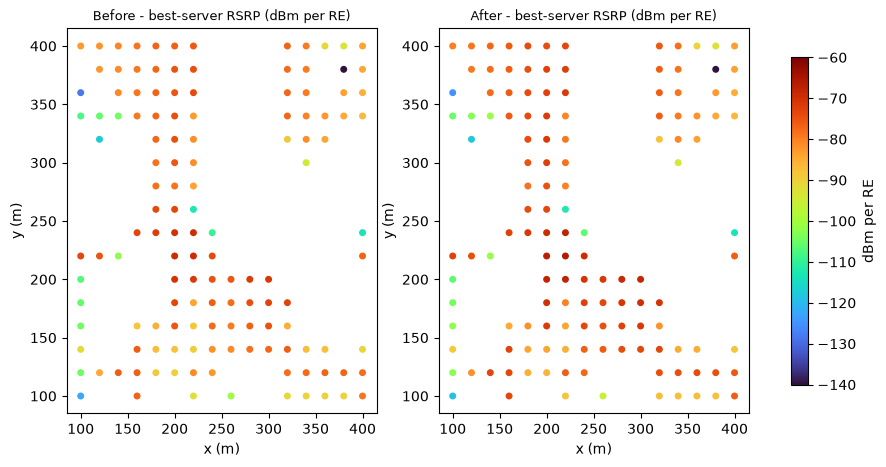

In [9]:
if "RESULT" not in globals():
    raise RuntimeError("This cell needs the setup cells above it. The kernel was restarted, or "
                       "cells 1-4 have not run yet: use Run > Run All Cells (or run cells 1-4 "
                       "first, then this one).")
# --- The result: read it here -------------------------------------------
# Everything the run concluded is printed in this cell's output: the
# recommended changes, the before -> after numbers and the RSRP maps.
# Nothing is written to a file and nothing is downloaded.
R = RESULT
print("=" * 66)
print("RESULT - mode:", R.get("mode"), "| function:", R.get("function"))
# one provenance per function that ran ("all" runs several)
parts = [R["provenance"]] if R.get("provenance") else []
if R.get("slice"):
    parts.append(R["slice"].get("provenance", "policy_guarded_accept"))
if R.get("audit"):
    parts.append("mcs_audit_guarded (per-sector detail below)")
if R.get("energy"):
    parts.append("energy_anchored_estimate")
prov = ", ".join(parts) if parts else "-"
print("Provenance:", prov)
if R.get("changes"):
    print("\nRecommended changes:")
    for c in R["changes"]:
        print("  -", c)
kb, ka = R.get("kpis_before"), R.get("kpis_after")
if kb and ka:
    print("\nBefore -> after (twin-verified):")
    for lbl, k, d in [("Coverage (%)", "coverage_pct", 1),
                      ("Median RSRP (dBm)", "median_rsrp", 1),
                      ("Edge RSRP p5 (dBm)", "edge_rsrp_p5", 1),
                      ("Median SINR (dB)", "median_sinr", 1),
                      ("Path availability (%)", "path_pct", 1),
                      ("Weighted SE (bit/s/Hz)", "capacity_weighted_se", 2)]:
        if k in kb and k in ka:
            print(f"  {lbl:26s} {kb[k]:>8.{d}f} -> {ka[k]:>8.{d}f}")
    if R.get("per_site_served_coverage"):
        print("\nPer-site served coverage (%):")
        for s, v in R["per_site_served_coverage"].items():
            f1 = lambda x: "-" if x is None else f"{x:.1f}"
            print(f"  {s}: {f1(v['before'])} -> {f1(v['after'])}")
if R.get("slice"):
    s = R["slice"]
    profs = {q["name"]: q for q in s["profiles"]}
    chosen = profs[s["chosen_profile"]]
    print("\nSlice / PRB - profile:", s["current_profile"], "->", s["chosen_profile"],
          "| scheduler:", chosen["scheduler"])
    print("  Reward - existing counters, existing shares:", round(s["counters_reward"], 2))
    print(f"  {'profile':16s} {'shares eMBB/URLLC/mMTC':24s} {'twin reward':>11s}")
    for q in s["profiles"]:
        mark = "  <- chosen" if q["name"] == s["chosen_profile"] else ("  (existing)" if q["name"] == s["current_profile"] else "")
        print(f"  {q['name']:16s} {str(q['shares']):24s} {q['reward']:>11.2f}{mark}")
if R.get("audit"):
    a = R["audit"]
    print("\nMCS audit - site:", a.get("site"))
    print(f"  {'sector':7s} {'offset':>7s} {'correct':>8s} {'SE gain':>8s} {'fit L1':>7s}")
    for i2, sec in enumerate(a["sectors"]):
        rec = sec.get("recommendation") or {}  # None when the sector needs no action
        print(f"  {i2 + 1:<7d} {sec['estimated_effective_offset_db']:>7.2f} "
              f"{rec.get('olla_offset_adjustment_db', 0):>+8.2f} "
              f"{sec['se_gain_relative'] * 100:>7.1f}% {sec['histogram_l1_distance']:>7.2f}")
        if sec.get("cap_binding") and rec:
            print("    MCS cap is binding in the twin - the recommendation raises the cap to",
                  rec.get("mcs_cap"))
if R.get("energy"):
    e = R["energy"]
    print(f"\nEnergy index: {e['index_before']:.0f} -> {e['index_after']:.1f} "
          f"(estimated saving {e['saving_pct']:.1f}% - anchored on the RANOpt energy "
          f"validation over the site's low-traffic hours; an estimate, not a twin trace)")
    for pl in e.get("plan", []):
        print("  -", pl)
for n in R.get("notes", []):
    print("Note:", n)
print("=" * 66)

maps = R.get("maps")
if maps:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for ax, key, ttl in [(axes[0], "before", "Before - best-server RSRP (dBm per RE)"),
                         (axes[1], "after", "After - best-server RSRP (dBm per RE)")]:
        pts = [(x, y, v) for x, y, v in zip(maps["x"], maps["y"], maps[key]) if v is not None]
        sc = ax.scatter([q[0] for q in pts], [q[1] for q in pts],
                        c=[q[2] for q in pts], cmap="turbo", vmin=-140, vmax=-60, s=16)
        ax.set_title(ttl, fontsize=9)
        ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
    fig.colorbar(sc, ax=axes, shrink=0.85, label="dBm per RE")
    plt.show()
